In [ ]:
import torch
import einops

In [ ]:
class Transgender(nn.Module):
    def __init__(self, data = 2):
        self.data = data


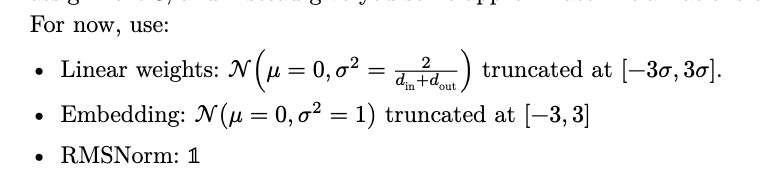

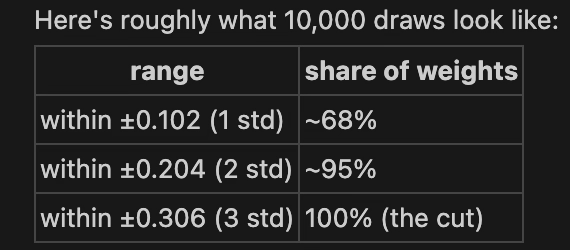

This is what the truncate distribution randomness of choosing that number


In [ ]:
from statistics import variance
from einops import einsum
from torch.nn.init import trunc_normal_
import torch.nn as nn
from math import sqrt 


def variance_and_std(in_features, out_features):
    
    variance = 2/(in_features+out_features)
    std = variance**(1/2)

    return variance,std

class Linear(nn.Module):
    def __init__(self, in_features=None, out_features=None, device=None, dtype=None):

        super().__init__()
        self.infeatures = in_features
        self.out_features = out_features
        self.device = device
        self.dtype = dtype
        self.weights = nn.Parameter(torch.empty((self.out_features, self.infeatures), dtype=dtype))# 128,64
        variance, std = variance_and_std(self.infeatures, self.out_features)
        self.weights = trunc_normal_(self.weights, mean=0, std = std, a = -3*std, b=3*std)
        # the weights will be from truncated normal distribution:


    def forward(self, x : torch.Tensor):
        output = einsum(x, self.weights, "... d_in, d_in d_out-> ... d_out") # b,t 64 (64 128)

        return output
    



In [39]:
test = Linear(4,12,64)

In [8]:
x = torch.randint(1,10,size=(3,2))
w = torch.randint(1,10,size=(3,2))


In [10]:
x @ w.T

tensor([[66, 35, 71],
        [24, 12, 24],
        [22,  9, 17]])

In [36]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

device

device(type='mps')